# 07 · Análisis del monitoreo, ética y resultado de negocio

Lee las tablas que llenaron los flujos `monitoreo` y `reentrenamiento` (esquema `PSET2_DB.PRODUCCION`) y produce las tablas y figuras de las secciones 6 a 9 del documento técnico. Las figuras se guardan en `docs/figs/`.

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import config as C
from src.datos import leer_sql
from src.pipeline import costo_negocio
from monitoreo.referencia import leer_referencia
from monitoreo.alertas import tabla_markdown
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 180); FIG = "/work/docs/figs/"
mon = leer_sql(f"SELECT * FROM {C.T_MONITOREO}").sort_values("ts").drop_duplicates(["lote_id","tipo","metrica","feature"], keep="last")
ale = leer_sql(f"SELECT * FROM {C.T_ALERTAS}")
ree = leer_sql(f"SELECT * FROM {C.T_REENTRENAMIENTOS}")
lotes = leer_sql(f"SELECT lote_id, MAX(con_deriva::INT) AS con_deriva FROM {C.T_LOTES} GROUP BY lote_id").sort_values("lote_id")
ref = leer_referencia()
deriva_lotes = set(lotes.loc[lotes["con_deriva"]==1, "lote_id"])
aprob = ree[ree["decision"]=="aprobado"]
def marcar(ax):
    for _, r in ree.iterrows():
        ax.axvline(r["lote_disparo"]+0.5, ls="--", color="#2e7d32" if r["decision"]=="aprobado" else "#9e9e9e")
        ax.text(r["lote_disparo"]+0.55, ax.get_ylim()[1], f"reentreno v{r['version_challenger']} ({r['decision']})", fontsize=8, va="top")
    for l in deriva_lotes: ax.axvspan(l-0.5, l+0.5, color="#f9a825", alpha=0.08)
def serie(tipo, metrica, feature=None):
    d = mon[(mon["tipo"]==tipo) & (mon["metrica"]==metrica)]
    if feature is not None: d = d[d["feature"]==feature]
    return d.set_index("lote_id")["valor"].sort_index()
print("Lotes con deriva inducida:", sorted(deriva_lotes)); print("Referencia:", json.dumps(ref["meta"], indent=1, default=str))

/usr/local/lib/python3.12/site-packages/snowflake/connector/connection/_connection.py:137: FutureWarning: enable_server_session_keep_alive_auto_detection was not set and defaults to True. In a future version, the default will change to None. Please provide an explicit value: True = check for running async queries before logout (queries are preserved); False/None = always send logout on close (async queries may be terminated by server). Logout behavior can also be overridden with server_session_keep_alive. See the connection parameter docs for more info.
  options = self.config.to_proto_options(


/usr/local/lib/python3.12/site-packages/snowflake/connector/connection/_connection.py:137: FutureWarning: enable_server_session_keep_alive_auto_detection was not set and defaults to True. In a future version, the default will change to None. Please provide an explicit value: True = check for running async queries before logout (queries are preserved); False/None = always send logout on close (async queries may be terminated by server). Logout behavior can also be overridden with server_session_keep_alive. See the connection parameter docs for more info.
  options = self.config.to_proto_options(


/usr/local/lib/python3.12/site-packages/snowflake/connector/connection/_connection.py:137: FutureWarning: enable_server_session_keep_alive_auto_detection was not set and defaults to True. In a future version, the default will change to None. Please provide an explicit value: True = check for running async queries before logout (queries are preserved); False/None = always send logout on close (async queries may be terminated by server). Logout behavior can also be overridden with server_session_keep_alive. See the connection parameter docs for more info.
  options = self.config.to_proto_options(


Lotes con deriva inducida: [9, 10, 11, 12, 13]
Referencia: {
 "version_champion": "1",
 "run_id": "972c63a668334b73a195ce78b0bb44ea",
 "umbral": 0.21999999999999997,
 "n_ref": 4339,
 "ref_desde": "2026-02-27 15:08:34",
 "ref_hasta": "2026-08-25 20:47:13",
 "tasa_priorizar_ref": 0.4265959898594146,
 "pct_negativa_ref": 0.3722055773219636,
 "pct_texto_vacio_ref": 0.0,
 "corte": "2026-08-25 20:47:13"
}


## 1. Umbrales de PSI: variación natural dentro del entrenamiento

In [2]:
nat = pd.DataFrame(ref["psi_natural"]).pivot_table(index="feature", columns="bloque", values="psi")
nat["máximo"] = nat.max(axis=1); display(nat.round(3))
print("Si el máximo natural queda bajo 0,25, ese umbral separa la variación normal entre períodos de un cambio real.")

bloque,1,2,3,4,máximo
feature,,,,,
banco,10.754,8.909,8.624,2.678,10.754
es_solo_simbolos,0.078,0.000,0.000,0.002,0.078
log_n_palabras,0.042,0.040,0.014,0.169,0.169
n_neg_lexico_cat,0.034,0.024,0.004,0.141,0.141
version_app_desconocida,0.010,0.005,0.002,0.026,0.026


Si el máximo natural queda bajo 0,25, ese umbral separa la variación normal entre períodos de un cambio real.


## 2. Alertas por lote y falsas alarmas

In [3]:
print(tabla_markdown())
piv = ale.pivot_table(index="lote_id", columns="nombre", values="id_alerta", aggfunc="count", fill_value=0)
piv = piv.reindex(lotes["lote_id"], fill_value=0); piv.insert(0, "con_deriva", lotes.set_index("lote_id")["con_deriva"])
display(piv)
falsas = ale[~ale["lote_id"].isin(deriva_lotes) & ale["nombre"].isin(["Deriva de una feature","Caída de desempeño (deriva conceptual)","Categorías no vistas"])]
print(f"Falsas alarmas (alertas de deriva o desempeño en lotes sin alterar): {len(falsas)}")
display(falsas[["lote_id","nombre","feature","valor","umbral"]])

| Alerta | Métrica | Umbral | Ventana | Severidad | Quién la recibe | Acción |
|---|---|---|---|---|---|---|
| Deriva de una feature | PSI de cada feature vs referencia (KS / chi² como respaldo) | PSI > 0.25 y p < 0.01 | 1 lote | Alta | Equipo de datos | Revisar la fuente y la ingesta; si el cambio es real, evaluar reentrenamiento |
| Deriva de las predicciones | PSI de la probabilidad predicha vs referencia | PSI > 0.25 | 1 lote | Media | Equipo de ciencia de datos | Revisar qué features explican el cambio y la carga del equipo de atención |
| Categorías no vistas | % de filas con banco no visto en entrenamiento | > 1% | 1 lote | Media | Equipo de datos | Incorporar la entidad al esquema y al entrenamiento; mientras tanto la API la rechaza (422) |
| Texto faltante | % de reseñas sin texto o con features nulas | > 5% sobre la referencia | 1 lote | Media | Equipo de datos | Revisar el extractor de Google Play y la capa Silver |
| Valores fuera de rango | % de filas fuera del rango de la

nombre,con_deriva,Categorías no vistas,Caída de desempeño (deriva conceptual),Deriva de las predicciones,Deriva de una feature,Entradas rechazadas
lote_id,,,,,,
1,0,0,0,1,1,0
2,0,0,0,0,1,0
3,0,0,0,0,1,0
4,0,0,0,0,1,0
5,0,0,0,0,1,0
6,0,0,0,0,1,0
7,0,0,0,0,1,0
8,0,0,0,0,1,0
9,1,1,0,1,2,1


Falsas alarmas (alertas de deriva o desempeño en lotes sin alterar): 8


,lote_id,nombre,feature,valor,umbral
1,1,Deriva de una feature,banco,1.489510,0.25
2,2,Deriva de una feature,banco,1.467446,0.25
3,3,Deriva de una feature,banco,1.393891,0.25
4,4,Deriva de una feature,banco,2.152203,0.25
5,5,Deriva de una feature,banco,2.105995,0.25
6,6,Deriva de una feature,banco,1.725441,0.25
7,7,Deriva de una feature,banco,1.772650,0.25
8,8,Deriva de una feature,banco,2.219310,0.25


## 3. Deriva de datos y deriva conceptual lote por lote

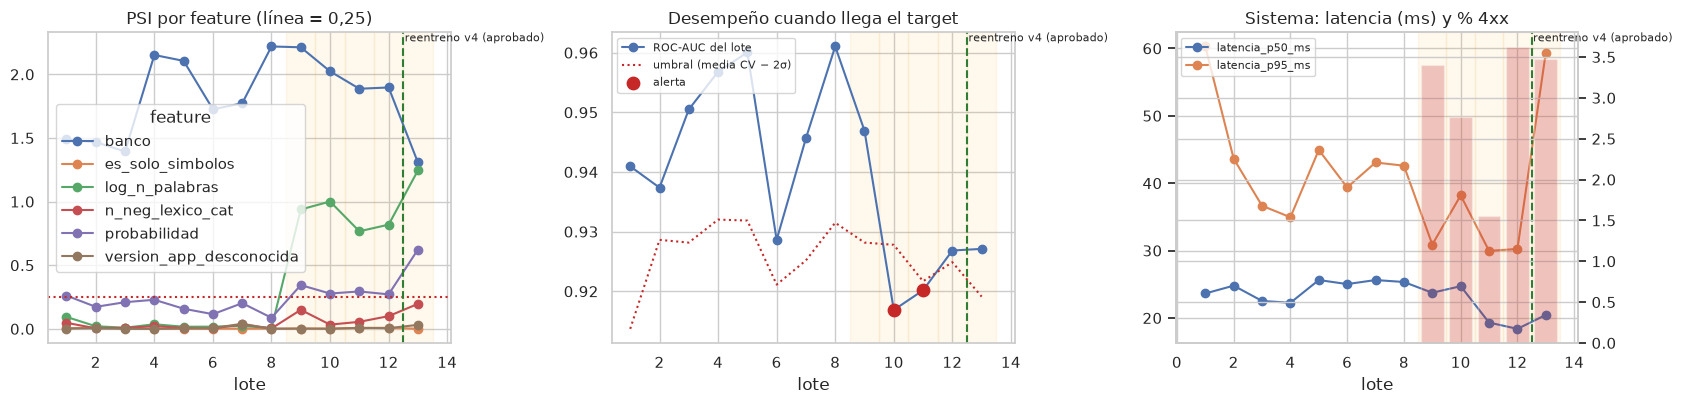

,lote,diagnóstico,acción,versión
111,1,Deriva de datos sin impacto,Registrar y vigilar; no reentrenar. Revisar co...,1
186,2,Deriva de datos sin impacto,Registrar y vigilar; no reentrenar. Revisar co...,1
264,3,Deriva de datos sin impacto,Registrar y vigilar; no reentrenar. Revisar co...,1
342,4,Deriva de datos sin impacto,Registrar y vigilar; no reentrenar. Revisar co...,1
417,5,Deriva de datos sin impacto,Registrar y vigilar; no reentrenar. Revisar co...,1
492,6,Deriva de datos sin impacto,Registrar y vigilar; no reentrenar. Revisar co...,1
567,7,Deriva de datos sin impacto,Registrar y vigilar; no reentrenar. Revisar co...,1
642,8,Deriva de datos sin impacto,Registrar y vigilar; no reentrenar. Revisar co...,1
720,9,Deriva de datos sin impacto,Registrar y vigilar; no reentrenar. Revisar co...,1
795,10,Deriva de datos con impacto,"Revisar la fuente (¿error de ingesta?) y, si e...",1


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
psi = mon[(mon["tipo"]=="deriva") & (mon["metrica"]=="psi")].pivot_table(index="lote_id", columns="feature", values="valor")
psi.plot(ax=ax[0], marker="o"); ax[0].axhline(C.PSI_ALERTA, color="#c62828", ls=":"); ax[0].set_title("PSI por feature (línea = 0,25)"); marcar(ax[0])
roc = mon[(mon["tipo"]=="modelo") & (mon["metrica"]=="roc_auc")].set_index("lote_id").sort_index()
ax[1].plot(roc.index, roc["valor"], marker="o", label="ROC-AUC del lote"); ax[1].plot(roc.index, roc["umbral"], ls=":", color="#c62828", label="umbral (media CV − 2σ)")
ax[1].scatter(roc.index[roc["estado"]=="alerta"], roc["valor"][roc["estado"]=="alerta"], color="#c62828", s=80, zorder=3, label="alerta")
ax[1].set_title("Desempeño cuando llega el target"); ax[1].legend(fontsize=8); marcar(ax[1])
for m_ in ["latencia_p50_ms","latencia_p95_ms"]: ax[2].plot(serie("sistema", m_), marker="o", label=m_)
ax2 = ax[2].twinx(); ax2.bar(serie("sistema","tasa_4xx").index, serie("sistema","tasa_4xx")*100, alpha=.25, color="#c62828", label="% 4xx")
ax[2].set_title("Sistema: latencia (ms) y % 4xx"); ax[2].legend(fontsize=8, loc="upper left"); marcar(ax[2])
for a in ax: a.set_xlabel("lote")
plt.tight_layout(); plt.savefig(FIG+"monitoreo_por_lote.png", dpi=150); plt.show()
diag = mon[mon["tipo"]=="diagnostico"][["lote_id","estado","detalle","version_modelo"]].sort_values("lote_id")
diag.columns = ["lote","diagnóstico","acción","versión"]; display(diag)

## 4. Reentrenamientos: champion vs challenger

In [5]:
cols = ["lote_disparo","motivo","lote_evaluacion","version_champion","version_challenger","costo_champion","costo_challenger",
        "sd_costo_cv","roc_auc_champion","roc_auc_challenger","regla_promueve","decision","motivo_decision"]
display(ree[cols].round(4))

,lote_disparo,motivo,lote_evaluacion,version_champion,version_challenger,costo_champion,costo_challenger,sd_costo_cv,roc_auc_champion,roc_auc_challenger,regla_promueve,decision,motivo_decision
0,12,desempeño: ROC-AUC bajo el umbral en 2 lotes s...,11,1,4,0.3943,0.2776,0.0462,0.9202,0.9233,True,aprobado,Challenger v4 reduce el costo por resena de 0....


## 5. Resultado de negocio lote por lote (sección 9)

Costo por reseña con FN = 5 y FP = 1 (supuesto del PSet #3). Alternativas: **regla de negocio** (proceso actual: palabras de queja), **no hacer nada** (ninguna reseña se prioriza) y **revisar todas**.

metrica,version,resenas,costo_modelo,costo_regla_negocio,costo_no_hacer_nada,costo_revisar_todas,% quejas priorizadas modelo,% quejas priorizadas regla,ahorro_total_vs_regla
lote_id,,,,,,,,,
1,1,232.0,0.203,0.560,1.315,0.737,91.803,60.656,83.0
2,1,447.0,0.195,0.649,1.913,0.617,94.737,69.006,203.0
3,1,429.0,0.147,0.555,1.643,0.671,97.163,69.504,175.0
4,1,501.0,0.118,0.583,1.567,0.687,98.089,66.242,233.0
5,1,347.0,0.156,0.669,1.902,0.620,96.212,66.667,178.0
6,1,346.0,0.205,0.627,1.604,0.679,94.595,64.865,146.0
7,1,301.0,0.189,0.615,1.512,0.698,94.505,62.637,128.0
8,1,334.0,0.171,0.608,1.766,0.647,95.763,67.797,146.0
9,1,312.0,0.365,0.968,1.795,0.641,83.929,48.214,188.0


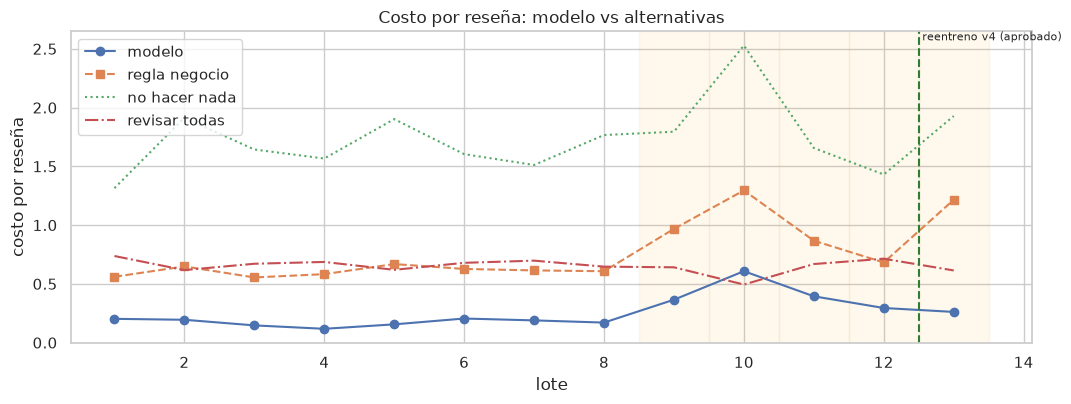

En 13 lotes: costo evitado frente a la regla = 2419 unidades (1 unidad = una revisión innecesaria; una queja sin atender = 5).
Quejas reales: 1683. El modelo priorizó 1524 (90.6%); la regla, 993 (59.0%): 531 quejas más atendidas a tiempo.
Revisiones innecesarias del modelo: 442


In [6]:
neg = mon[mon["tipo"]=="negocio"].pivot_table(index="lote_id", columns="metrica", values="valor")
neg["ahorro_vs_regla_por_resena"] = neg["costo_regla_negocio"] - neg["costo_modelo"]
n_lote = mon[(mon["tipo"]=="modelo") & (mon["metrica"]=="n_predicciones")].set_index("lote_id")["valor"]
neg["resenas"] = n_lote; neg["ahorro_total_vs_regla"] = neg["ahorro_vs_regla_por_resena"] * neg["resenas"]
neg["version"] = mon[(mon["tipo"]=="negocio") & (mon["metrica"]=="costo_modelo")].set_index("lote_id")["version_modelo"]
neg["% quejas priorizadas modelo"] = neg["quejas_priorizadas_modelo"]/neg["quejas_reales"]*100
neg["% quejas priorizadas regla"] = neg["quejas_priorizadas_regla"]/neg["quejas_reales"]*100
tabla = neg[["version","resenas","costo_modelo","costo_regla_negocio","costo_no_hacer_nada","costo_revisar_todas",
             "% quejas priorizadas modelo","% quejas priorizadas regla","ahorro_total_vs_regla"]].round(3)
display(tabla); tabla.to_csv("/work/docs/negocio_por_lote.csv")
fig, ax = plt.subplots(figsize=(11, 4.2))
for c, est in [("costo_modelo","o-"),("costo_regla_negocio","s--"),("costo_no_hacer_nada",":"),("costo_revisar_todas","-.")]:
    ax.plot(neg.index, neg[c], est, label=c.replace("costo_","").replace("_"," "))
ax.set_xlabel("lote"); ax.set_ylabel("costo por reseña"); ax.set_title("Costo por reseña: modelo vs alternativas"); ax.legend(); marcar(ax)
plt.tight_layout(); plt.savefig(FIG+"negocio_por_lote.png", dpi=150); plt.show()
total = neg["ahorro_total_vs_regla"].sum(); quejas = neg["quejas_reales"].sum()
extra = (neg["quejas_priorizadas_modelo"]-neg["quejas_priorizadas_regla"]).sum()
print(f"En {len(neg)} lotes: costo evitado frente a la regla = {total:.0f} unidades "
      f"(1 unidad = una revisión innecesaria; una queja sin atender = 5).")
print(f"Quejas reales: {quejas:.0f}. El modelo priorizó {neg['quejas_priorizadas_modelo'].sum():.0f} "
      f"({neg['quejas_priorizadas_modelo'].sum()/quejas:.1%}); la regla, {neg['quejas_priorizadas_regla'].sum():.0f} "
      f"({neg['quejas_priorizadas_regla'].sum()/quejas:.1%}): {extra:.0f} quejas más atendidas a tiempo.")
print(f"Revisiones innecesarias del modelo: {neg['revisiones_innecesarias_modelo'].sum():.0f}")

## 6. Ética: desempeño por subgrupo y costo de cada error (sección 8)

In [7]:
df = leer_sql(f"""SELECT p.decision, p.version_modelo, l.* FROM {C.T_PREDICCIONES} p
     JOIN {C.T_LOTES} l ON p.review_id = l.review_id AND p.lote_id = l.lote_id""")
df["pred"] = (df["decision"]=="priorizar").astype(int); df["y"] = df["es_negativa"].astype(int)
df["longitud"] = np.where(df["n_palabras"] <= 5, "corta (≤5 palabras)", "larga (>5)")
def resumen(g):
    tp = ((g.pred==1)&(g.y==1)).sum(); fn = ((g.pred==0)&(g.y==1)).sum(); fp = ((g.pred==1)&(g.y==0)).sum()
    return pd.Series({"n": len(g), "% negativas": g.y.mean()*100, "recall": tp/max(g.y.sum(),1),
                      "precisión": tp/max(g.pred.sum(),1), "tasa priorizar": g.pred.mean(),
                      "quejas no atendidas (FN)": fn, "revisiones innecesarias (FP)": fp, "costo": costo_negocio(g.y, g.pred)})
sin_deriva = df[~df["lote_id"].isin(deriva_lotes)]
for col in ["banco", "longitud", "version_app_desconocida"]:
    t = sin_deriva.groupby(col).apply(resumen, include_groups=False).round(3); display(t)
    t.to_csv(f"/work/docs/subgrupo_{col}.csv")
print("Lotes con deriva, por longitud:"); display(df[df["lote_id"].isin(deriva_lotes)].groupby("longitud").apply(resumen, include_groups=False).round(3))

/usr/local/lib/python3.12/site-packages/snowflake/connector/connection/_connection.py:137: FutureWarning: enable_server_session_keep_alive_auto_detection was not set and defaults to True. In a future version, the default will change to None. Please provide an explicit value: True = check for running async queries before logout (queries are preserved); False/None = always send logout on close (async queries may be terminated by server). Logout behavior can also be overridden with server_session_keep_alive. See the connection parameter docs for more info.
  options = self.config.to_proto_options(


,n,% negativas,recall,precisión,tasa priorizar,quejas no atendidas (FN),revisiones innecesarias (FP),costo
banco,,,,,,,,
Banco Bolivariano,47.0,55.319,1.000,0.812,0.681,0.0,6.0,0.128
Banco Guayaquil,529.0,19.093,0.921,0.608,0.289,8.0,60.0,0.189
Banco Pichincha,1893.0,36.714,0.954,0.791,0.443,32.0,175.0,0.177
Banco del Austro,20.0,30.000,1.000,0.857,0.350,0.0,1.0,0.050
Banco del Pacífico,3.0,100.000,1.000,1.000,1.000,0.0,0.0,0.000
Cooperativa JEP,38.0,50.000,0.947,0.720,0.658,1.0,7.0,0.316
Diners Club (blu),292.0,19.863,0.983,0.722,0.271,1.0,22.0,0.092
Produbanco,115.0,64.348,1.000,0.841,0.765,0.0,14.0,0.122


,n,% negativas,recall,precisión,tasa priorizar,quejas no atendidas (FN),revisiones innecesarias (FP),costo
longitud,,,,,,,,
corta (≤5 palabras),1676.0,11.993,0.831,0.687,0.145,34.0,76.0,0.147
larga (>5),1261.0,61.935,0.990,0.787,0.779,8.0,209.0,0.197


,n,% negativas,recall,precisión,tasa priorizar,quejas no atendidas (FN),revisiones innecesarias (FP),costo
version_app_desconocida,,,,,,,,
0,2604.0,32.680,0.957,0.763,0.410,37.0,253.0,0.168
1,333.0,39.339,0.962,0.797,0.474,5.0,32.0,0.171


Lotes con deriva, por longitud:


,n,% negativas,recall,precisión,tasa priorizar,quejas no atendidas (FN),revisiones innecesarias (FP),costo
longitud,,,,,,,,
corta (≤5 palabras),1467.0,31.766,0.758,0.767,0.314,113.0,107.0,0.458
larga (>5),342.0,68.713,0.983,0.822,0.822,4.0,50.0,0.205


## 7. Criterios de retirada: estado observado

In [8]:
ult = neg.tail(2)
crit = pd.DataFrame([
 {"criterio": "Costo del modelo ≥ regla de negocio 2 lotes seguidos (aun después de reentrenar)",
  "observado": f"{int((neg['costo_modelo'] >= neg['costo_regla_negocio']).rolling(2).sum().max() if len(neg)>1 else 0)} lotes seguidos máx.",
  "respuesta": "Interruptor de respaldo: decide la regla; reunión de retiro"},
 {"criterio": "Recall de un banco < 0,80 en 2 lotes seguidos",
  "observado": f"recall mínimo por banco (sin deriva): {sin_deriva.groupby('banco').apply(lambda g: ((g.pred==1)&(g.y==1)).sum()/max(g.y.sum(),1), include_groups=False).min():.3f}",
  "respuesta": "Ajustar el umbral para ese banco o excluirlo del modelo (regla de negocio)"},
 {"criterio": "ROC-AUC bajo el umbral en 2 lotes después de un reentrenamiento aprobado",
  "observado": str(roc[roc["version_modelo"].isin(aprob["version_challenger"].astype(str))]["estado"].tolist()),
  "respuesta": "Retirar: volver a la regla y revisar la formulación"},
 {"criterio": "Tasa 5xx > 1 % o respaldo automático > 0 % por más de 1 lote",
  "observado": f"máx. 5xx = {serie('sistema','tasa_5xx').max():.2%}",
  "respuesta": "Rollback de la versión de la API (imagen anterior en GHCR)"}])
crit

,criterio,observado,respuesta
0,Costo del modelo ≥ regla de negocio 2 lotes se...,0 lotes seguidos máx.,Interruptor de respaldo: decide la regla; reun...
1,"Recall de un banco < 0,80 en 2 lotes seguidos",recall mínimo por banco (sin deriva): 0.921,Ajustar el umbral para ese banco o excluirlo d...
2,ROC-AUC bajo el umbral en 2 lotes después de u...,['ok'],Retirar: volver a la regla y revisar la formul...
3,Tasa 5xx > 1 % o respaldo automático > 0 % por...,máx. 5xx = 0.00%,Rollback de la versión de la API (imagen anter...
